# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

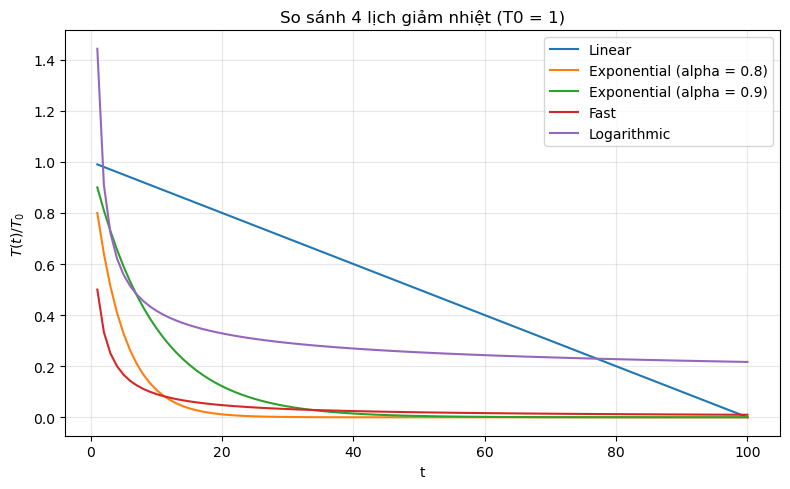

In [6]:
import os
os.makedirs("figs", exist_ok=True)
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.title("So sánh 4 lịch giảm nhiệt (T0 = 1)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figs/sa_schedules_compare.png", dpi=150)
plt.show()

### Nhận xét đồ thị so sánh (cùng $T_0=1$, $t=1\ldots100$)
- **Logarithmic** giảm **chậm nhất**: $T(100)=1/\ln 101\approx 0{,}217$ (vẫn còn ~22% $T_0$). Lưu ý $T(1)=1/\ln 2\approx 1{,}44>T_0$ vì $\ln(1+t)<1$ khi $t<e-1$; hàm không xác định tại $t=0$ (chia cho 0).
- **Fast** giảm **rất nhanh lúc đầu** ($T(1)=0{,}5$, $T(10)\approx0{,}09$) rồi trườn chậm ($T(100)\approx0{,}0099$).
- **Mũ:** $\alpha$ càng gần 1 càng nguội chậm: $\alpha=0{,}8$ nguội nhanh hơn $\alpha=0{,}9$ ($0{,}8^{100}\approx2\times10^{-10}$ so với $0{,}9^{100}\approx2{,}7\times10^{-5}$).
- **Tuyến tính** với $\eta=0{,}01$ giảm đều và chạm **đúng 0 tại $t=100$**; nếu tiếp tục, $T<0$ là vô nghĩa nên cần chặn $T\ge T_{\min}>0$ (nếu không $e^{-\Delta/T}$ chia cho 0 / mũ dương).

## Khảo sát tham số $\alpha$, $\eta$, $T_0$
Với $\Delta=1$ cố định, ta tính xác suất chấp nhận bước xấu $p(t)=e^{-\Delta/T(t)}$ và đo **thời gian duy trì bước xấu**: $t^*$ = số bước đầu tiên mà $p(t)<\varepsilon=0{,}01$ (tương đương $T<\Delta/\ln 100\approx0{,}217$). Nếu $T_0$ nhỏ hơn ngưỡng này thì $t^*=0$ (ngay từ đầu đã “lạnh”). Dùng $t$ tới 5000 để thấy khác biệt.

In [7]:
def accept_prob(T, delta=1.0):
    """p = exp(-delta/T); T <= 0 -> 0 (không chấp nhận bước xấu)."""
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    ok = T > 1e-12
    out[ok] = np.exp(-delta / T[ok])
    return out

def t_star(T_arr, t_arr, delta=1.0, eps=0.01):
    """Bước đầu tiên mà xác suất chấp nhận bước xấu < eps (None nếu chưa bao giờ)."""
    p = accept_prob(T_arr, delta)
    below = np.where(p < eps)[0]
    return int(t_arr[below[0]]) if len(below) else None

tt = np.arange(1, 5001)
DELTA, EPS = 1.0, 0.01
print(f"Ngưỡng nhiệt T < {DELTA/np.log(1/EPS):.3f} thì p < {EPS}")

rows = []
# (a) alpha, T0 = 1
for a in [0.8, 0.9, 0.95, 0.99]:
    rows.append(("Mũ", f"T0=1, alpha={a}", t_star(temperature_exponential(tt, 1, a), tt)))
# (b) eta, T0 = 1
for e in [0.0005, 0.001, 0.005, 0.01, 0.02]:
    rows.append(("Tuyến tính", f"T0=1, eta={e}", t_star(temperature_linear(tt, 1, e), tt)))
# (c) T0 cho fast, log, mũ(0.9), tuyến tính(0.01)
for T0 in [0.5, 1, 2, 5]:
    rows.append(("Fast", f"T0={T0}", t_star(temperature_fast(tt, T0), tt)))
for T0 in [0.5, 1, 2, 5]:
    rows.append(("Logarithmic", f"T0={T0}", t_star(temperature_logarithmic(tt, T0), tt)))
for T0 in [0.5, 1, 2, 5]:
    rows.append(("Mũ", f"T0={T0}, alpha=0.9", t_star(temperature_exponential(tt, T0, 0.9), tt)))

print(f"{'Lịch':<12}{'Cấu hình':<24}{'t* (p<0.01, Δ=1)':>18}")
for r in rows:
    print(f"{r[0]:<12}{r[1]:<24}{str(r[2]) if r[2] is not None else '>5000':>18}")

Ngưỡng nhiệt T < 0.217 thì p < 0.01
Lịch        Cấu hình                  t* (p<0.01, Δ=1)
Mũ          T0=1, alpha=0.8                          7
Mũ          T0=1, alpha=0.9                         15
Mũ          T0=1, alpha=0.95                        30
Mũ          T0=1, alpha=0.99                       152
Tuyến tính  T0=1, eta=0.0005                      1566
Tuyến tính  T0=1, eta=0.001                        783
Tuyến tính  T0=1, eta=0.005                        157
Tuyến tính  T0=1, eta=0.01                          79
Tuyến tính  T0=1, eta=0.02                          40
Fast        T0=0.5                                   2
Fast        T0=1                                     4
Fast        T0=2                                     9
Fast        T0=5                                    23
Logarithmic T0=0.5                                   9
Logarithmic T0=1                                    99
Logarithmic T0=2                                 >5000
Logarithmic T0=5             

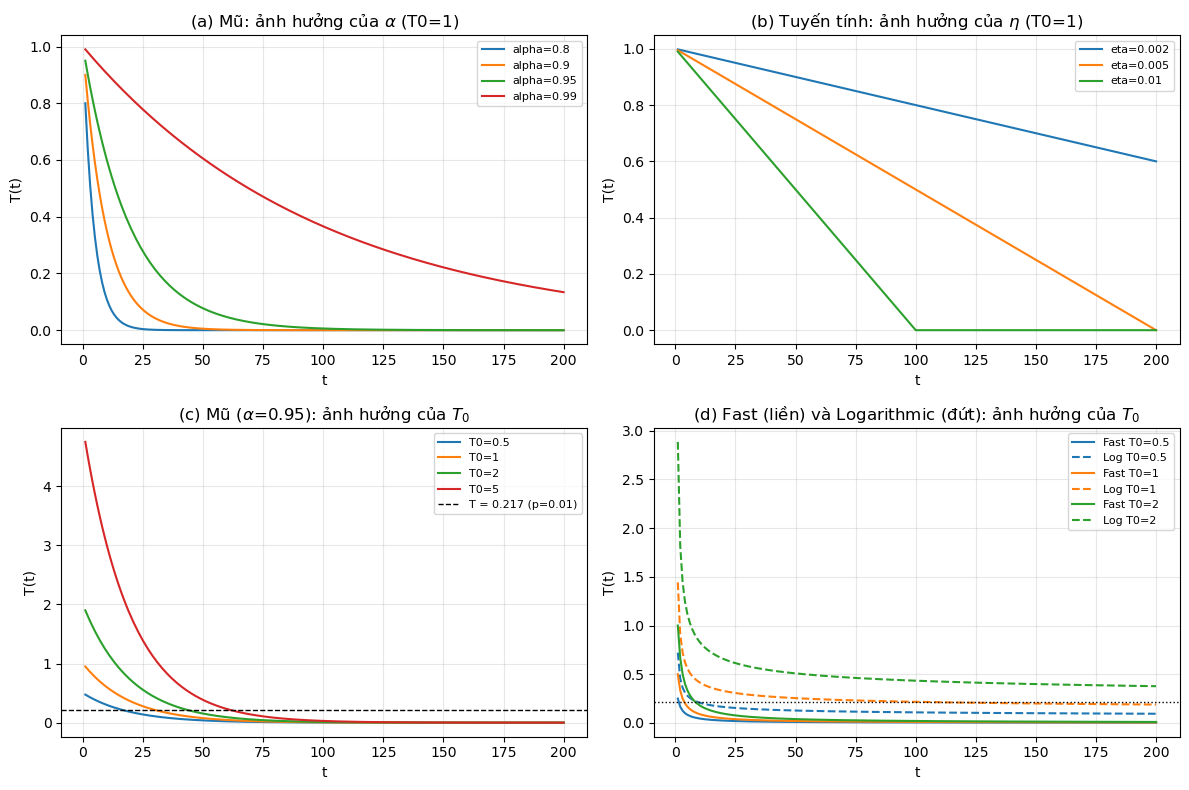

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.ravel()
t = np.arange(1, 201)

# (a) ảnh hưởng alpha
for a in [0.8, 0.9, 0.95, 0.99]:
    ax[0].plot(t, temperature_exponential(t, 1, a), label=f"alpha={a}")
ax[0].set_title(r"(a) Mũ: ảnh hưởng của $\alpha$ (T0=1)")

# (b) ảnh hưởng eta
for e in [0.002, 0.005, 0.01]:
    ax[1].plot(t, np.clip(temperature_linear(t, 1, e), 0, None), label=f"eta={e}")
ax[1].set_title(r"(b) Tuyến tính: ảnh hưởng của $\eta$ (T0=1)")

# (c) ảnh hưởng T0 (mũ alpha=0.95)
for T0 in [0.5, 1, 2, 5]:
    ax[2].plot(t, temperature_exponential(t, T0, 0.95), label=f"T0={T0}")
ax[2].axhline(DELTA/np.log(1/EPS), ls="--", c="k", lw=1, label="T = 0.217 (p=0.01)")
ax[2].set_title(r"(c) Mũ ($\alpha$=0.95): ảnh hưởng của $T_0$")

# (d) ảnh hưởng T0 cho Fast (nét liền) và Logarithmic (nét đứt)
for T0, col in zip([0.5, 1, 2], ["C0", "C1", "C2"]):
    ax[3].plot(t, temperature_fast(t, T0), c=col, label=f"Fast T0={T0}")
    ax[3].plot(t, temperature_logarithmic(t, T0), c=col, ls="--", label=f"Log T0={T0}")
ax[3].axhline(DELTA/np.log(1/EPS), ls=":", c="k", lw=1)
ax[3].set_title(r"(d) Fast (liền) và Logarithmic (đứt): ảnh hưởng của $T_0$")

for a_ in ax:
    a_.set_xlabel("t"); a_.set_ylabel("T(t)"); a_.legend(fontsize=8); a_.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figs/sa_param_sweeps.png", dpi=150); plt.show()

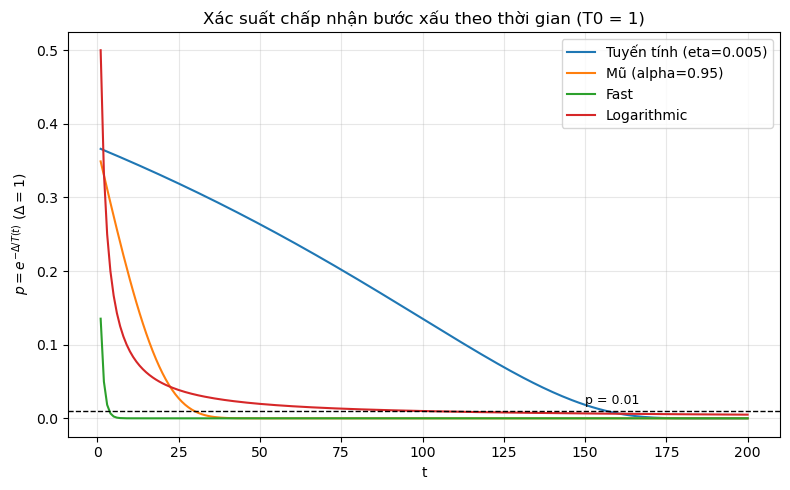

In [9]:
# Xác suất chấp nhận bước xấu p(t) = exp(-Δ/T(t)), Δ = 1, T0 = 1 (cùng điều kiện với đồ thị so sánh)
t = np.arange(1, 201)
cfg = {
    "Tuyến tính (eta=0.005)": temperature_linear(t, 1, 0.005),
    "Mũ (alpha=0.95)": temperature_exponential(t, 1, 0.95),
    "Fast": temperature_fast(t, 1),
    "Logarithmic": temperature_logarithmic(t, 1),
}
plt.figure(figsize=(8, 5))
for name, T in cfg.items():
    plt.plot(t, accept_prob(T, DELTA), label=name)
plt.axhline(EPS, ls="--", c="k", lw=1)
plt.text(150, EPS + 0.01, "p = 0.01", fontsize=9)
plt.xlabel("t"); plt.ylabel(r"$p=e^{-\Delta/T(t)}$ ($\Delta=1$)")
plt.title("Xác suất chấp nhận bước xấu theo thời gian (T0 = 1)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("figs/sa_accept_prob.png", dpi=150); plt.show()

### Nhận xét ảnh hưởng của $\alpha$, $\eta$, $T_0$ (xem bảng $t^*$ và các hình)
- **$\alpha$ (lịch mũ):** $\alpha$ càng **gần 1** thì $T$ giảm càng chậm, bước xấu được chấp nhận càng lâu. $t^*$ xấp xỉ $\ln(T_{thr}/T_0)/\ln\alpha$, với $T_{thr}\approx0{,}217$; ví dụ $T_0=1$: $\alpha=0{,}8\to t^*\approx7$, $0{,}9\to15$, $0{,}95\to30$, $0{,}99\to152$. $\alpha$ nhỏ → nguội rất nhanh, SA gần như thành Hill Climbing.
- **$\eta$ (lịch tuyến tính):** $\eta$ **nhỏ** → nguội chậm. Thời điểm nhiệt về 0 là $t=T_0/\eta$, và $t^*=(T_0-T_{thr})/\eta$ – tỉ lệ nghịch với $\eta$. $\eta$ lớn (0,02) chỉ giữ bước xấu khoảng 40 bước.
- **$T_0$:** tăng $T_0$ làm **mọi lịch đều kéo dài giai đoạn chấp nhận bước xấu** (thêm một khoảng “khám phá”). Với mũ: mỗi lần nhân đôi $T_0$ thêm $\ln 2/\ln(1/\alpha)$ bước (≈6,6 bước khi $\alpha=0{,}9$) – hiệu ứng **logarit/chậm**. Với *logarithmic* và *fast* tác động lớn hơn nhiều vì $T$ giảm theo luỹ thừa/ln: $t^*$ tăng gần như **tuyến tính theo $T_0$** (fast: $t^*\approx T_0/T_{thr}-1$) hoặc **mũ theo $T_0$** (log: $t^*\approx e^{T_0/T_{thr}}-1$). $T_0$ phải cùng cỡ với $\Delta$ điển hình của bài toán: quá nhỏ → mất khả năng thoát cực trị; quá lớn → đi ngẫu nhiên lãng phí.

### Lịch nào chấp nhận bước xấu lâu nhất?
Với cấu hình mặc định của notebook ($T_0=1$, $\Delta=1$, ngưỡng $p<0{,}01$), thứ tự từ lâu nhất đến ngắn nhất là: **Logarithmic ($t^*=99$) > Tuyến tính $\eta=0{,}01$ (79) > Mũ $\alpha=0{,}9$ (15) > Mũ $\alpha=0{,}8$ (7) > Fast (4)**. Thứ tự này **không cố định**: chỉ cần tăng $T_0$ lên 2 thì lịch logarithmic không hạ xuống dưới ngưỡng trong 5000 bước (nguội cực chậm), còn mũ $\alpha=0{,}99$ (152) hay tuyến tính $\eta=0{,}005$ (157) vượt cả logarithmic ở $T_0=1$. Kết luận: *logarithmic* chấp nhận bước xấu lâu nhất khi $T_0$ không nhỏ, nhưng thời gian này phụ thuộc mạnh vào tham số, nên khi so sánh phải giữ **cùng $T_0$, cùng ngân sách vòng lặp**.

## Tổng hợp & lựa chọn lịch cho thí nghiệm n-Queens / TSP
| Lịch | Tốc độ nguội | Ưu điểm | Nhược điểm | Gợi ý dùng |
|---|---|---|---|---|
| Logarithmic | rất chậm | Có bảo đảm lý thuyết tìm nghiệm toàn cục khi $t\to\infty$ nếu $T_0\ge$ rào năng lượng lớn nhất (Hajek, 1988) | Quá chậm với ngân sách hữu hạn; không xác định tại $t=0$ | Ít dùng thực tế, chỉ để so sánh |
| Mũ | tuỳ $\alpha$ | Dễ chỉnh, T luôn dương, phổ biến nhất | Phải chọn $\alpha$ (0,95–0,99 hay dùng) | **Khuyến nghị cho n-Queens/TSP** |
| Tuyến tính | đều rồi chạm 0 | Đơn giản, biết trước thời điểm kết thúc $T_0/\eta$ | Cần chặn $T>0$; cuối quá trình là leo đồi thuần tuý | Dùng khi biết rõ ngân sách vòng lặp |
| Fast | rất nhanh đầu, chậm sau | Khám phá ngắn rồi khai thác, ít chi phí | Nguội quá sớm → dễ kẹt cực trị nếu $T_0$ nhỏ | Dùng khi ngân sách ít, $T_0$ lớn |

**Lưu ý đối chiếu với Bài 4:** đề yêu cầu thử ít nhất hai lịch nhiệt trong SA của n-Queens (Task 5, thành viên Búp). Từ khảo sát này, đề xuất so sánh **mũ ($\alpha=0{,}95$–$0{,}99$)** và **fast/tuyến tính** với cùng $T_0$, cùng seed, cùng ngân sách vòng lặp; nhớ đặt $T_0$ cùng cỡ với $\Delta$ (với n-Queens $\Delta$ thường là 1–3 xung đột, nên $T_0\approx1$–$5$).

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)